# Learning to act in an arithmetic environment

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shoaibphysics/arithmetic-post-training/blob/main/notebooks/03_target_game.ipynb)

Notebook 02 trained the model to generate a single answer using GRPO.
Here, an attempt contains several actions and environment responses.

The task is to reach a target by combining three starting numbers.
The model chooses the moves; a Python environment performs the arithmetic,
enforces the rules, and determines success.

We will teach the interaction format, measure the starting agent,
and apply GRPO to complete games.

### Setup

Use the project's Python environment locally. In Colab, select a GPU
runtime for training.

Later sections will load the saved GRPO adapter from notebook 02.
Run outputs go into `runs/agent/`; figures and small result tables
go into `assets/agent/`.

In [1]:
import sys

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    %pip install -q transformers==5.18.0 trl==1.16.0 peft==0.21.2 datasets==5.1.0 accelerate==1.15.0 pandas==3.0.6 matplotlib==3.11.2
    %pip install -q --no-deps git+https://github.com/shoaibphysics/arithmetic-post-training.git@main

In [2]:
import json
from pathlib import Path

import pandas as pd

from arithmetic_post_training.target_game import TargetGameEnv

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    project_root = Path("/content/drive/MyDrive/arithmetic-post-training")
else:
    project_root = Path.cwd()
    if project_root.name == "notebooks":
        project_root = project_root.parent

run_dir = project_root / "runs" / "agent"
asset_dir = project_root / "assets" / "agent"

run_dir.mkdir(parents=True, exist_ok=True)
asset_dir.mkdir(parents=True, exist_ok=True)

print("Run outputs:", run_dir)
print("README assets:", asset_dir)

Run outputs: /Users/shoaibakhtar/Developer/reasoning-models/arithmetic-post-training/runs/agent
README assets: /Users/shoaibakhtar/Developer/reasoning-models/arithmetic-post-training/assets/agent


### The target-number game

Start with three numbers and a target. Each move combines two available
numbers using addition, subtraction, or multiplication.

The selected numbers are removed and their result is appended to the list.
This ensures that each starting number is used exactly once.
Operators may repeat, and intermediate results may be negative.

For example:

| Available numbers | Move | Updated numbers |
|-------------------|------|-----------------|
| `[2, 3, 4]` | `2 + 3` | `[4, 5]` |
| `[4, 5]` | `4 * 5` | `[20]` |

With target 20, this game succeeds.

Actions select zero-based positions in the **current** list.
For `[2, 3, 4]`, indices 0 and 1 select 2 and 3.
After the first move, those same indices select 4 and 5.

An episode allows three attempted moves. Invalid moves return an error
without changing the numbers, but consume an attempt.

The episode ends when one number remains or the attempt budget is exhausted.
Its reward is 1 only when the final remaining number equals the target;
otherwise it is 0.

### Agent inputs, actions, and observations

The agent receives the game instructions, current state, and interaction
history. It generates a tool call such as:

```text
<tool_call>
{"name": "combine", "arguments": {"i": 0, "j": 1, "op": "+"}}
</tool_call>
```

TRL parses this generated call and invokes `env.combine(0, 1, "+")`.
The environment returns an observation:

```json
{"numbers":[4,5],"target":20,"done":false,"success":false,"attempts_left":2}
```

That observation becomes context for the next model response. The model
then selects its next move using the updated list. When the environment
reports `done: true`, we will teach the model to finish with `done`.

Success is determined by the environment's state, not by the model
claiming that it succeeded.

During RL, only model-generated tokens contribute to the policy loss.
Environment observations provide context but are excluded from that loss.

### A scripted interaction

First, we choose the moves ourselves to demonstrate the environment.
This checks the state transitions and saved history; it is not a model result.

The later agent will generate these actions itself.

In [3]:
env = TargetGameEnv()

print("Initial state:", env.reset(numbers=[2, 3, 4], target=20))

env.combine(0, 1, "+")
env.combine(0, 1, "*")

trajectory = pd.DataFrame([
    {
        "action": step["action"],
        **json.loads(step["observation"]),
    }
    for step in env.history
])

trajectory.to_csv(run_dir / "environment-demo.csv", index=False)
trajectory

Initial state: {"numbers":[2,3,4],"target":20,"done":false,"success":false,"attempts_left":3}


,action,numbers,target,done,success,attempts_left
0,"{'i': 0, 'j': 1, 'op': '+'}","[4, 5]",20,False,False,2
1,"{'i': 0, 'j': 1, 'op': '*'}",[20],20,True,True,1


### Solvable puzzles

Each puzzle contains three integers from 1 to 9, with repetitions allowed.
We enumerate possible two-move solutions using addition, subtraction, and
multiplication, keeping targets from 1 to 100. Every puzzle therefore has
at least one solution.

We create 512 training, 32 validation, and 64 test puzzles. Puzzles sharing
the same starting numbers stay in the same split, even when their targets
differ.

We store one successful action sequence for supervised training.
The agent receives only the task instructions and environment state
during evaluation and RL. Any valid solution is accepted.

In [4]:
from arithmetic_post_training.target_game import make_game_data, make_demonstration

data = make_game_data(
    n_train=512,
    n_validation=32,
    n_test=64,
    seed=42,
)

for split, rows in data.items():
    (run_dir / f"{split}.json").write_text(
        json.dumps(rows, indent=2) + "\n"
    )

pd.DataFrame({
    "split": list(data),
    "puzzles": [len(rows) for rows in data.values()],
})

,split,puzzles
0,train,512
1,validation,32
2,test,64


### Supervised interaction examples

Our previous checkpoint learned to return integer answers. We now prepare
a short supervised warm-up that teaches successful action choices and the
tool-calling format:

**Task → action → observation → action → observation → done**

For each training puzzle, the solver supplies the actions and the environment
produces the observations. During training, only assistant tokens contribute
to the loss; environment observations provide context.

We will evaluate this warm-up checkpoint before applying GRPO, so that
supervised learning and reinforcement learning have separate comparisons.

The example below is a scripted training conversation, not a model prediction.

In [5]:
demonstrations = [
    make_demonstration(row) for row in data["train"]
]

(run_dir / "warmup-train.jsonl").write_text(
    "".join(json.dumps(row) + "\n" for row in demonstrations)
)

example = data["train"][0]
print("Training demonstrations:", len(demonstrations))
print("Numbers:", example["numbers"], "Target:", example["target"])
print()

for message in demonstrations[0]["messages"][2:]:
    if message.get("tool_calls"):
        args = message["tool_calls"][0]["function"]["arguments"]
        print(f"Agent: combine({args['i']}, {args['j']}, {args['op']!r})")
    else:
        print(f"{message['role'].capitalize()}: {message['content']}")

/Users/shoaibakhtar/Developer/reasoning-models/arithmetic-post-training/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Training demonstrations: 512
Numbers: [4, 8, 8] Target: 32

Agent: combine(2, 0, '-')
Tool: {"numbers":[8,4],"target":32,"done":false,"success":false,"attempts_left":2}
Agent: combine(0, 1, '*')
Tool: {"numbers":[32],"target":32,"done":true,"success":true,"attempts_left":1}
Assistant: done


### Supervised warm-up

We start from the GRPO checkpoint saved in notebook 02 and train on
512 successful game conversations for two epochs.

The trainable parameters are the existing LoRA adapter and four existing
chat/tool token embeddings. These embeddings let the base checkpoint learn
the message and tool-call delimiters. All other base weights remain frozen.

The objective is next-token prediction on assistant messages: tool calls
and the final `done` response. Instructions and environment observations
provide context but do not contribute directly to the loss.

This stage teaches both successful moves and the interaction format.
We will measure its game success separately before applying GRPO.

In [6]:
from datasets import Dataset
from transformers import set_seed
from trl import SFTConfig, SFTTrainer

from arithmetic_post_training.agent import load_agent

set_seed(42)

model, tokenizer = load_agent(
    project_root / "runs" / "grpo" / "adapter",
    train_new_tokens=True,
)
tokenizer.padding_side = "right"

print("Device:", model.device)
model.print_trainable_parameters()

example = demonstrations[0]
encoded = tokenizer.apply_chat_template(
    example["messages"],
    tools=json.loads(example["tools"]),
    return_dict=True,
    return_assistant_tokens_mask=True,
)

print("\nTokens receiving supervision:")
print(tokenizer.decode([
    token
    for token, mask in zip(
        encoded["input_ids"], encoded["assistant_masks"]
    )
    if mask
]))

Loading weights: 100%|██████████| 290/290 [00:00<00:00, 643.01it/s]


Device: mps:0
trainable params: 8,801,792 || all params: 502,834,560 || trainable%: 1.7504

Tokens receiving supervision:

<tool_call>
{"name": "combine", "arguments": {"i": 2, "j": 0, "op": "-"}}
</tool_call><|im_end|>

<tool_call>
{"name": "combine", "arguments": {"i": 0, "j": 1, "op": "*"}}
</tool_call><|im_end|>

done<|im_end|>



In [7]:
warmup_args = SFTConfig(
    output_dir=str(run_dir / "warmup"),
    num_train_epochs=2,
    per_device_train_batch_size=2,
    gradient_accumulation_steps=8,
    learning_rate=2e-4,
    warmup_steps=4,
    optim="adamw_torch",
    max_length=640,
    assistant_only_loss=True,
    completion_only_loss=False,
    gradient_checkpointing=False,
    bf16=False,
    fp16=False,
    dataloader_pin_memory=False,
    logging_steps=8,
    save_strategy="no",
    report_to="none",
    disable_tqdm=True,
    seed=42,
)

trainer = SFTTrainer(
    model=model,
    args=warmup_args,
    train_dataset=Dataset.from_list(demonstrations),
    processing_class=tokenizer,
)

warmup_result = trainer.train()

Truncating train dataset: 100%|██████████| 512/512 [00:00<00:00, 16878.09 examples/s]
Dropping fully masked examples from train dataset: 100%|██████████| 512/512 [00:00<00:00, 39212.70 examples/s]
[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 151645}.


{'loss': '1.5', 'grad_norm': '14.53', 'learning_rate': '0.00019', 'entropy': '1.264', 'mean_token_accuracy': '0.8139', 'num_tokens': '6.033e+04', 'epoch': '0.25'}
{'loss': '0.4454', 'grad_norm': '7.778', 'learning_rate': '0.0001633', 'entropy': '0.9525', 'mean_token_accuracy': '0.937', 'num_tokens': '1.206e+05', 'epoch': '0.5'}
{'loss': '0.09663', 'grad_norm': '0.4815', 'learning_rate': '0.0001367', 'entropy': '0.218', 'mean_token_accuracy': '0.9584', 'num_tokens': '1.81e+05', 'epoch': '0.75'}
{'loss': '0.07381', 'grad_norm': '0.2609', 'learning_rate': '0.00011', 'entropy': '0.07929', 'mean_token_accuracy': '0.9582', 'num_tokens': '2.413e+05', 'epoch': '1'}
{'loss': '0.06991', 'grad_norm': '0.1779', 'learning_rate': '8.333e-05', 'entropy': '0.07182', 'mean_token_accuracy': '0.9606', 'num_tokens': '3.016e+05', 'epoch': '1.25'}
{'loss': '0.06836', 'grad_norm': '0.3322', 'learning_rate': '5.667e-05', 'entropy': '0.06793', 'mean_token_accuracy': '0.9608', 'num_tokens': '3.619e+05', 'epoch'

In [8]:
warmup_adapter = run_dir / "warmup-adapter"

trainer.save_model(str(warmup_adapter))
tokenizer.save_pretrained(warmup_adapter)

pd.DataFrame(trainer.state.log_history).to_csv(
    run_dir / "warmup-log.csv", index=False
)

(run_dir / "warmup-config.json").write_text(
    json.dumps(warmup_args.to_dict(), indent=2) + "\n"
)
(run_dir / "warmup-metrics.json").write_text(
    json.dumps(warmup_result.metrics, indent=2) + "\n"
)

print("Saved checkpoint:", warmup_adapter)

Saved checkpoint: /Users/shoaibakhtar/Developer/reasoning-models/arithmetic-post-training/runs/agent/warmup-adapter


### Does the agent solve games?

We evaluate the saved warm-up checkpoint on 32 validation puzzles,
sampling four attempts per puzzle: 128 episodes in total.

Each episode allows three attempted moves and a total completion budget
of 256 tokens, including inserted tool observations. The saved solutions
are not supplied to the agent.

Success requires reaching the target in the environment. We also record
tool use, invalid actions, and the fraction of puzzles with both successful
and unsuccessful attempts. These mixed groups can provide a relative
reward signal for GRPO.

We use TRL's environment interaction loop and call only `evaluate()`.
No model weights are updated. The test set remains reserved for the
final comparison.

In [9]:
import gc
from importlib import reload

from trl import GRPOTrainer
from arithmetic_post_training import agent

reload(agent)

del trainer, model
gc.collect()

model, tokenizer = agent.load_agent(warmup_adapter)
tokenizer.padding_side = "left"

recorder = agent.EpisodeRecorder(
    run_dir / "warmup-validation-rollouts.jsonl"
)

probe = GRPOTrainer(
    model=model,
    args=agent.game_config(run_dir / "warmup-validation"),
    train_dataset=agent.game_dataset(data["train"]),
    eval_dataset=agent.game_dataset(data["validation"]),
    processing_class=tokenizer,
    environment_factory=TargetGameEnv,
    reward_funcs=recorder,
)

set_seed(123)
validation_metrics = probe.evaluate()

Loading weights: 100%|██████████| 290/290 [00:00<00:00, 390.48it/s]
/var/folders/5f/6cjjqxjx7h1dgk4h0dxv2qxc0000gn/T/ipykernel_53726/2334867226.py:19: UserWarning: You are using 'environment_factory', which is an experimental feature. This API may change or be removed at any time without prior notice. Silence this warning by setting environment variable TRL_EXPERIMENTAL_SILENCE=1.
  probe = GRPOTrainer(


{'eval_loss': '4.889e-09', 'eval_model_preparation_time': '0.0059', 'eval_runtime': '124.9', 'eval_samples_per_second': '0.256', 'eval_steps_per_second': '0.064', 'eval_num_tokens': '0', 'eval_completions/mean_length': '62.24', 'eval_completions/min_length': '62', 'eval_completions/max_length': '62.97', 'eval_completions/clipped_ratio': '0', 'eval_completions/mean_terminated_length': '62.24', 'eval_completions/min_terminated_length': '62', 'eval_completions/max_terminated_length': '62.97', 'eval_tools/call_frequency': '2.008', 'eval_tools/failure_frequency': '0', 'eval_rewards/game_success/mean': '0.1094', 'eval_rewards/game_success/std': '0.1923', 'eval_reward': '0.1094', 'eval_reward_std': '0.1923', 'eval_frac_reward_zero_std': '0.625', 'eval_entropy': '0.07645', 'eval_clip_ratio/low_mean': '0', 'eval_clip_ratio/high_mean': '0', 'eval_clip_ratio/region_mean': '0', 'eval_clip_ratio/low_min': '0', 'eval_clip_ratio/high_max': '0', 'epoch': 0}


In [10]:
episodes = pd.DataFrame(recorder.records)
groups = episodes.groupby("task_id")["reward"].agg(["min", "max"])

summary = pd.DataFrame([{
    "episodes": len(episodes),
    "success_rate": episodes["reward"].mean(),
    "tool_use_rate": episodes["used_tool"].mean(),
    "invalid_actions": episodes["invalid_actions"].sum(),
    "mixed_group_fraction": (groups["min"] < groups["max"]).mean(),
}])

summary.to_csv(asset_dir / "warmup-validation.csv", index=False)

(run_dir / "warmup-validation-metrics.json").write_text(
    json.dumps(validation_metrics, indent=2) + "\n"
)
(run_dir / "warmup-validation-config.json").write_text(
    json.dumps(probe.args.to_dict(), indent=2) + "\n"
)

summary.round(3)

,episodes,success_rate,tool_use_rate,invalid_actions,mixed_group_fraction
0,128,0.109,1.0,1,0.375


### GRPO over complete games

The warm-up agent solved 14 of 128 validation episodes. It used the tool
in every episode, but choosing successful moves remains difficult.
Twelve of 32 puzzles produced both successful and unsuccessful attempts.

We now sample four complete games per training puzzle. Each game receives
reward 1 for reaching the target and 0 otherwise. GRPO compares these
rewards within each puzzle's group and updates the generated action tokens.
Environment observations remain context and are excluded from the loss.

We run 40 updates with learning rate 1e-5, keeping the same sampling
settings and interaction budgets. No demonstration solutions are supplied.

The centered GRPO loss can remain close to zero even with nonzero gradients.
After training, we will compare the saved warm-up and GRPO checkpoints on
the same held-out test puzzles.

In [11]:
del probe, model
gc.collect()

set_seed(42)
model, tokenizer = agent.load_agent(warmup_adapter)
tokenizer.padding_side = "left"

train_recorder = agent.EpisodeRecorder(
    run_dir / "grpo-rollouts.jsonl"
)

grpo_args = agent.game_config(
    run_dir / "grpo",
    max_steps=40,
    learning_rate=1e-5,
    warmup_steps=4,
)

trainer = GRPOTrainer(
    model=model,
    args=grpo_args,
    train_dataset=agent.game_dataset(data["train"]),
    processing_class=tokenizer,
    environment_factory=TargetGameEnv,
    reward_funcs=train_recorder,
)

grpo_result = trainer.train()

Loading weights: 100%|██████████| 290/290 [00:00<00:00, 298.76it/s]
/var/folders/5f/6cjjqxjx7h1dgk4h0dxv2qxc0000gn/T/ipykernel_53726/663112748.py:19: UserWarning: You are using 'environment_factory', which is an experimental feature. This API may change or be removed at any time without prior notice. Silence this warning by setting environment variable TRL_EXPERIMENTAL_SILENCE=1.
  trainer = GRPOTrainer(
[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 151645}.


{'loss': '3.725e-09', 'grad_norm': '0', 'learning_rate': '1e-05', 'num_tokens': '1.543e+04', 'completions/mean_length': '62', 'completions/min_length': '62', 'completions/max_length': '62', 'completions/clipped_ratio': '0', 'completions/mean_terminated_length': '62', 'completions/min_terminated_length': '62', 'completions/max_terminated_length': '62', 'tools/call_frequency': '2', 'tools/failure_frequency': '0', 'rewards/game_success/mean': '0.05', 'rewards/game_success/std': '0.1414', 'reward': '0.05', 'reward_std': '0.1414', 'frac_reward_zero_std': '0.8', 'entropy': '0.07648', 'clip_ratio/low_mean': '0', 'clip_ratio/high_mean': '0', 'clip_ratio/region_mean': '0', 'clip_ratio/low_min': '0', 'clip_ratio/high_max': '0', 'step_time': '5.868', 'epoch': '0.01953'}
{'loss': '0', 'grad_norm': '0', 'learning_rate': '8.611e-06', 'num_tokens': '3.086e+04', 'completions/mean_length': '62', 'completions/min_length': '62', 'completions/max_length': '62', 'completions/clipped_ratio': '0', 'completio

In [12]:
grpo_adapter = run_dir / "grpo-adapter"

trainer.save_model(str(grpo_adapter))
tokenizer.save_pretrained(grpo_adapter)

pd.DataFrame(trainer.state.log_history).to_csv(
    run_dir / "grpo-log.csv", index=False
)

(run_dir / "grpo-config.json").write_text(
    json.dumps(grpo_args.to_dict(), indent=2) + "\n"
)
(run_dir / "grpo-metrics.json").write_text(
    json.dumps(grpo_result.metrics, indent=2) + "\n"
)

print("Saved checkpoint:", grpo_adapter)

Saved checkpoint: /Users/shoaibakhtar/Developer/reasoning-models/arithmetic-post-training/runs/agent/grpo-adapter


### Held-out comparison

We compare the saved warm-up and GRPO checkpoints on 64 unseen test
puzzles, sampling four attempts per puzzle: 256 episodes per checkpoint.

Both checkpoints receive the same puzzles, tools, sampling settings,
and action and token budgets. We reset the sampling seed before each
evaluation.

We report successful episodes divided by total episodes, along with
tool use and invalid actions. This comparison measures the effect of
the GRPO stage after supervised warm-up.

In [13]:
del trainer, model
gc.collect()

results = []

for name, checkpoint in [
    ("warmup", warmup_adapter),
    ("grpo", grpo_adapter),
]:
    print(f"\nEvaluating {name}")

    model, tokenizer = agent.load_agent(checkpoint)
    tokenizer.padding_side = "left"

    recorder = agent.EpisodeRecorder(
        run_dir / f"{name}-test-rollouts.jsonl"
    )

    probe = GRPOTrainer(
        model=model,
        args=agent.game_config(run_dir / f"{name}-test"),
        train_dataset=agent.game_dataset(data["train"]),
        eval_dataset=agent.game_dataset(data["test"]),
        processing_class=tokenizer,
        environment_factory=TargetGameEnv,
        reward_funcs=recorder,
    )

    set_seed(2026)
    metrics = probe.evaluate()
    frame = pd.DataFrame(recorder.records)

    results.append({
        "checkpoint": name,
        "episodes": len(frame),
        "successes": int(frame["reward"].sum()),
        "success_rate": frame["reward"].mean(),
        "tool_use_rate": frame["used_tool"].mean(),
        "invalid_actions": int(frame["invalid_actions"].sum()),
    })

    (run_dir / f"{name}-test-metrics.json").write_text(
        json.dumps(metrics, indent=2) + "\n"
    )
    (run_dir / f"{name}-test-config.json").write_text(
        json.dumps(probe.args.to_dict(), indent=2) + "\n"
    )

    del probe, model
    gc.collect()

results = pd.DataFrame(results)
results.to_csv(asset_dir / "test-results.csv", index=False)
results.round(3)


Evaluating warmup


Loading weights: 100%|██████████| 290/290 [00:00<00:00, 405.15it/s]
/var/folders/5f/6cjjqxjx7h1dgk4h0dxv2qxc0000gn/T/ipykernel_53726/537288863.py:19: UserWarning: You are using 'environment_factory', which is an experimental feature. This API may change or be removed at any time without prior notice. Silence this warning by setting environment variable TRL_EXPERIMENTAL_SILENCE=1.
  probe = GRPOTrainer(


{'eval_loss': '2.678e-09', 'eval_model_preparation_time': '0.0063', 'eval_runtime': '257', 'eval_samples_per_second': '0.249', 'eval_steps_per_second': '0.062', 'eval_num_tokens': '0', 'eval_completions/mean_length': '62', 'eval_completions/min_length': '62', 'eval_completions/max_length': '62', 'eval_completions/clipped_ratio': '0', 'eval_completions/mean_terminated_length': '62', 'eval_completions/min_terminated_length': '62', 'eval_completions/max_terminated_length': '62', 'eval_tools/call_frequency': '2', 'eval_tools/failure_frequency': '0', 'eval_rewards/game_success/mean': '0.04297', 'eval_rewards/game_success/std': '0.07933', 'eval_reward': '0.04297', 'eval_reward_std': '0.07933', 'eval_frac_reward_zero_std': '0.8438', 'eval_entropy': '0.07627', 'eval_clip_ratio/low_mean': '0', 'eval_clip_ratio/high_mean': '0', 'eval_clip_ratio/region_mean': '0', 'eval_clip_ratio/low_min': '0', 'eval_clip_ratio/high_max': '0', 'epoch': 0}

Evaluating grpo


Loading weights: 100%|██████████| 290/290 [00:00<00:00, 415.21it/s]
/var/folders/5f/6cjjqxjx7h1dgk4h0dxv2qxc0000gn/T/ipykernel_53726/537288863.py:19: UserWarning: You are using 'environment_factory', which is an experimental feature. This API may change or be removed at any time without prior notice. Silence this warning by setting environment variable TRL_EXPERIMENTAL_SILENCE=1.
  probe = GRPOTrainer(


{'eval_loss': '2.678e-09', 'eval_model_preparation_time': '0.0057', 'eval_runtime': '255.9', 'eval_samples_per_second': '0.25', 'eval_steps_per_second': '0.063', 'eval_num_tokens': '0', 'eval_completions/mean_length': '62', 'eval_completions/min_length': '62', 'eval_completions/max_length': '62', 'eval_completions/clipped_ratio': '0', 'eval_completions/mean_terminated_length': '62', 'eval_completions/min_terminated_length': '62', 'eval_completions/max_terminated_length': '62', 'eval_tools/call_frequency': '2', 'eval_tools/failure_frequency': '0', 'eval_rewards/game_success/mean': '0.04688', 'eval_rewards/game_success/std': '0.08054', 'eval_reward': '0.04688', 'eval_reward_std': '0.08054', 'eval_frac_reward_zero_std': '0.8438', 'eval_entropy': '0.07454', 'eval_clip_ratio/low_mean': '0', 'eval_clip_ratio/high_mean': '0', 'eval_clip_ratio/region_mean': '0', 'eval_clip_ratio/low_min': '0', 'eval_clip_ratio/high_max': '0', 'epoch': 0}


,checkpoint,episodes,successes,success_rate,tool_use_rate,invalid_actions
0,warmup,256,11,0.043,1.0,3
1,grpo,256,12,0.047,1.0,1


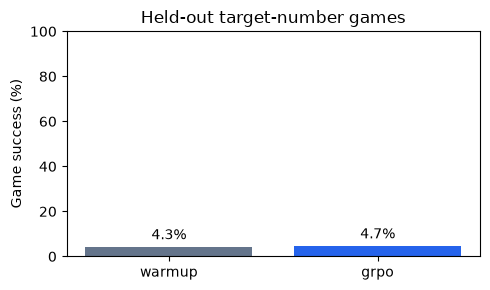

In [14]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5, 3))

bars = ax.bar(
    results["checkpoint"],
    100 * results["success_rate"],
    color=["#64748b", "#2563eb"],
)
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set(
    ylabel="Game success (%)",
    title="Held-out target-number games",
    ylim=(0, 100),
)

fig.tight_layout()
fig.savefig(asset_dir / "test-success.png", dpi=160)
plt.show()

### Interpretation

We evaluated both checkpoints on 64 held-out puzzles, with four sampled
attempts per puzzle and identical interaction budgets.

| Checkpoint | Successful episodes | Success rate |
|------------|--------------------:|-------------:|
| Supervised warm-up | 11 / 256 | 4.30% |
| After GRPO | 12 / 256 | 4.69% |

GRPO produced one additional successful episode, a difference of
0.39 percentage points. This single-seed experiment does not provide
convincing evidence of improved held-out performance.

Every test episode used the tool. Invalid actions were rare: three before
GRPO and one afterward. The agent learned the interaction format, while
choosing moves that reach the target remained difficult.

During training, only 18 of 80 sampled groups contained different rewards.
The remaining groups had zero relative advantages, limiting the available
learning signal.

The near-zero policy loss is compatible with centered advantages and our
one-update GRPO configuration. Nonzero gradients and changes in the saved
adapter weights confirm that training updates occurred.

This notebook demonstrates a stateful arithmetic environment, supervised
interaction training, trajectory-level GRPO, and held-out evaluation.
Stronger game-solving performance remains future work.